# Predicting Adverse Birth Outcomes Using Machine Learning


---



### A Population-Level Study of Maternal Demographics, Behaviors, and Prenatal Care

---


**Study Objective:** Develop machine learning models to predict low birth weight, preterm birth, and co-occurring LBW and PTB from maternal demographic, behavioral, physical, and prenatal care characteristics.


**Dataset:** CDC National Vital Statistics System / NBER U.S. Natality Dataset



---



| Target | Definition |
|---|---|
| Low birth weight (LBW) | birth weight < 2,500 g |
| Preterm birth (PTB) | gestational age < 37 completed weeks |
| Preterm Low Birth Weight (PLBW) | LBW **and** PTB in the same birth |



---


**Primary Features**
- Maternal age, race, and education
- Pre-pregnancy body mass index and gestational weight gain
- Tobacco use and WIC participation
- Timing of the first prenatal care visit

**Design:** 3 targets (LBW, PTB, PLBW) x 3 models (Logistic Regression, Random Forest, XGBoost) = 9 independent binary classifiers. Each target gets its own cohort (births with a known label), its own 70/15/15 train/validation/test split, its own decision threshold (tuned on validation), and its own test-set evaluation. All targets use the same predictor set.


**Evaluation:** As all 3 target outcomes are relatively uncommon, **average precision (PR-AUC) and recall** are the primary evaluation metrics. ROC-AUC, precision, and F1-score are included as secondary measures.


**Analysis Flow**
1. Setup and configuration
2. Data loading
3. Cleaning and target definition
4. Exploratory data analysis
5. Splits, models, and training
6. Threshold selection and test-set evaluation
7. Model interpretation (SHAP)
8. Discussion and limitations

## 1. Setup and Configuration

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import gc
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')


# Primary colors: Blue (#8FC1E3), Pink (#F4A6B8), Purple (#B9A4DB)
baby_palette = ['#8FC1E3', '#F4A6B8', '#B9A4DB', '#A2E8DD', '#FCE2DB', '#DFD3E3']
sns.set_theme(style='whitegrid', palette=sns.color_palette(baby_palette))
plt.rcParams['patch.force_edgecolor'] = True
plt.rcParams['patch.facecolor'] = '#8FC1E3'
plt.rcParams['grid.color'] = '#F2F2F2'

In [ ]:
# ---- QUICK ACCESS ITEMS ----
RANDOM_STATE = 42
DATA_PATH = '/content/drive/MyDrive/natality2024us.csv'

# 'both'   -> combined = low birth weight AND preterm
# 'either' -> combined = low birth weight OR preterm
COMBINED_RULE = 'both'

# Predictors (outcome source variables are excluded to prevent target leakage)
NUMERIC_COLS = ['maternal_age', 'prenatal_care_month', 'bmi', 'weight_gain']
CATEGORICAL_COLS = ['maternal_race', 'maternal_education', 'wic_participation', 'tobacco_use']
FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS

# The three prediction targets: column name -> display settings
TARGETS = {
    'low_birth_weight': {'label': 'Low Birth Weight', 'short': 'LBW',      'color': '#8FC1E3'},
    'preterm_birth':    {'label': 'Preterm Birth',    'short': 'PTB',      'color': '#F4A6B8'},
    'combined_ptb_lbw': {'label': 'Preterm Low Birth Weight (PLBW)' , 'short': 'PLBW', 'color': '#B9A4DB'},
}
MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'XGBoost']

# Raw CDC column -> clean name
COLUMN_MAPPING = {
    'dplural': 'plurality',
    'dbwt': 'birth_weight_grams',
    'combgest': 'gestational_age_weeks',
    'mager': 'maternal_age',
    'mrace6': 'maternal_race',
    'meduc': 'maternal_education',
    'bmi': 'bmi',
    'wtgain': 'weight_gain',
    'cig_rec': 'tobacco_use',
    'wic': 'wic_participation',
    'precare': 'prenatal_care_month',
}

# CDC "unknown" codes to convert to NaN (BMI is handled separately: 99.9)
UNKNOWN_CODES = {
    'birth_weight_grams': 9999,
    'gestational_age_weeks': 99,
    'maternal_education': 9,
    'prenatal_care_month': 99,
    'weight_gain': 99,
    'tobacco_use': 'U',
    'wic_participation': 'U',
}

## 2. Data Loading


In [ ]:
def load_singleton_births(path, column_mapping, chunk_size=150_000):
    """Read only the mapped columns, keep singleton births, return a renamed DataFrame."""
    header = pd.read_csv(path, nrows=0)
    lower_to_actual = {c.lower(): c for c in header.columns}

    missing = sorted(set(column_mapping) - set(lower_to_actual))
    if missing:
        print(f'Columns not found in file: {missing}')

    rename_dict = {lower_to_actual[k]: v for k, v in column_mapping.items() if k in lower_to_actual}
    plurality_col = next((c for c, v in rename_dict.items() if v == 'plurality'), None)

    chunks = []
    for chunk in pd.read_csv(path, usecols=list(rename_dict), chunksize=chunk_size, low_memory=False):
        if plurality_col is not None:
            chunk = chunk[chunk[plurality_col] == 1]
        for col in chunk.select_dtypes(include=['float64']).columns:
            chunk[col] = pd.to_numeric(chunk[col], downcast='float')
        for col in chunk.select_dtypes(include=['int64']).columns:
            chunk[col] = pd.to_numeric(chunk[col], downcast='integer')
        chunks.append(chunk)

    df = pd.concat(chunks, ignore_index=True).rename(columns=rename_dict)
    del chunks
    gc.collect()
    return df


df = load_singleton_births(DATA_PATH, COLUMN_MAPPING)
print(f'Singleton dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())

Singleton dataset: 3,526,370 rows x 11 columns


,maternal_age,maternal_race,maternal_education,prenatal_care_month,wic_participation,tobacco_use,bmi,weight_gain,plurality,gestational_age_weeks,birth_weight_grams
0,30,2,3,3,N,N,20.799999,4,1,38,2897
1,28,6,6,3,N,N,20.400000,40,1,38,3175
2,41,1,6,2,N,N,22.700001,28,1,37,2095
3,29,1,4,3,N,N,26.400000,99,1,38,3078
4,28,1,6,2,N,N,21.500000,31,1,39,3070


## 3. Cleaning and Target Definition


In [ ]:
df.info()
print('\nDuplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3526370 entries, 0 to 3526369
Data columns (total 11 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   maternal_age           int8   
 1   maternal_race          int8   
 2   maternal_education     int8   
 3   prenatal_care_month    int8   
 4   wic_participation      object 
 5   tobacco_use            object 
 6   bmi                    float32
 7   weight_gain            int8   
 8   plurality              int8   
 9   gestational_age_weeks  int8   
 10  birth_weight_grams     int16  
dtypes: float32(1), int16(1), int8(7), object(2)
memory usage: 97.5+ MB

Duplicate rows: 2110


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
maternal_age,3526370.0,NaN,NaN,NaN,29.638146,5.817651,12.0,25.0,30.0,34.0,50.0
maternal_race,3526370.0,NaN,NaN,NaN,1.532908,1.148649,1.0,1.0,1.0,2.0,6.0
maternal_education,3526370.0,NaN,NaN,NaN,4.541015,1.870386,1.0,3.0,4.0,6.0,9.0
prenatal_care_month,3526370.0,NaN,NaN,NaN,4.835702,13.276966,0.0,2.0,3.0,3.0,99.0
wic_participation,3526370,3,N,2370149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tobacco_use,3526370,3,N,3425686,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,3526370.0,NaN,NaN,NaN,29.623672,12.991024,13.0,22.9,26.6,32.099998,99.900002
weight_gain,3526370.0,NaN,NaN,NaN,31.354285,19.281152,0.0,20.0,29.0,40.0,99.0
plurality,3526370.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
gestational_age_weeks,3526370.0,NaN,NaN,NaN,38.700161,3.208431,17.0,38.0,39.0,40.0,99.0


In [ ]:
def recode_unknowns(df):
    """Convert CDC unknown codes to NaN. Returns (clean copy, summary of unknown/missing counts)."""
    out = df.copy()
    rows = []

    for col, code_value in UNKNOWN_CODES.items():
        n_unknown = int(out[col].isna().sum() + out[col].eq(code_value).sum())
        out.loc[out[col].eq(code_value), col] = np.nan
        rows.append({'Variable': col, 'Unknown / Missing': n_unknown})

    bmi_unknown = np.isclose(out['bmi'], 99.9, atol=0.01)
    rows.append({'Variable': 'bmi', 'Unknown / Missing': int(out['bmi'].isna().sum() + bmi_unknown.sum())})
    out.loc[bmi_unknown, 'bmi'] = np.nan

    summary = pd.DataFrame(rows)
    summary['Percent'] = (100 * summary['Unknown / Missing'] / len(out)).round(2)
    return out, summary.sort_values('Percent', ascending=False).reset_index(drop=True)


def add_targets(df, combined_rule=COMBINED_RULE):
    """Add the three binary targets. A target is NaN when its source variables are unknown."""
    out = df.copy()

    bw_ok = out['birth_weight_grams'].gt(0)       # NaN -> False
    ga_ok = out['gestational_age_weeks'].gt(0)
    out['low_birth_weight'] = np.where(bw_ok, (out['birth_weight_grams'] < 2500).astype(int), np.nan)
    out['preterm_birth'] = np.where(ga_ok, (out['gestational_age_weeks'] < 37).astype(int), np.nan)

    # Combined is only defined when BOTH source outcomes are known
    both_known = out[['low_birth_weight', 'preterm_birth']].notna().all(axis=1)
    lbw, ptb = out['low_birth_weight'] == 1, out['preterm_birth'] == 1
    hit = (lbw & ptb) if combined_rule == 'both' else (lbw | ptb)
    out['combined_ptb_lbw'] = np.where(both_known, hit.astype(int), np.nan)
    return out


df_clean, unknown_summary = recode_unknowns(df)
df_clean = add_targets(df_clean)

print('Unknown / missing values after CDC-code recoding:')
display(unknown_summary)

print('\nPredictor missingness used by the models:')
display(pd.DataFrame({
    'Missing Count': df_clean[FEATURE_COLS].isna().sum(),
    'Missing Percent': (df_clean[FEATURE_COLS].isna().mean() * 100).round(2),
}).sort_values('Missing Percent', ascending=False))

Unknown / missing values after CDC-code recoding:


,Variable,Unknown / Missing,Percent
0,weight_gain,105470,2.99
1,bmi,86035,2.44
2,prenatal_care_month,67842,1.92
3,maternal_education,66953,1.90
4,wic_participation,41940,1.19
5,tobacco_use,17190,0.49
6,gestational_age_weeks,4522,0.13
7,birth_weight_grams,2840,0.08



Predictor missingness used by the models:


,Missing Count,Missing Percent
weight_gain,105470,2.99
bmi,86035,2.44
prenatal_care_month,67842,1.92
maternal_education,66953,1.90
wic_participation,41940,1.19
tobacco_use,17190,0.49
maternal_age,0,0.00
maternal_race,0,0.00


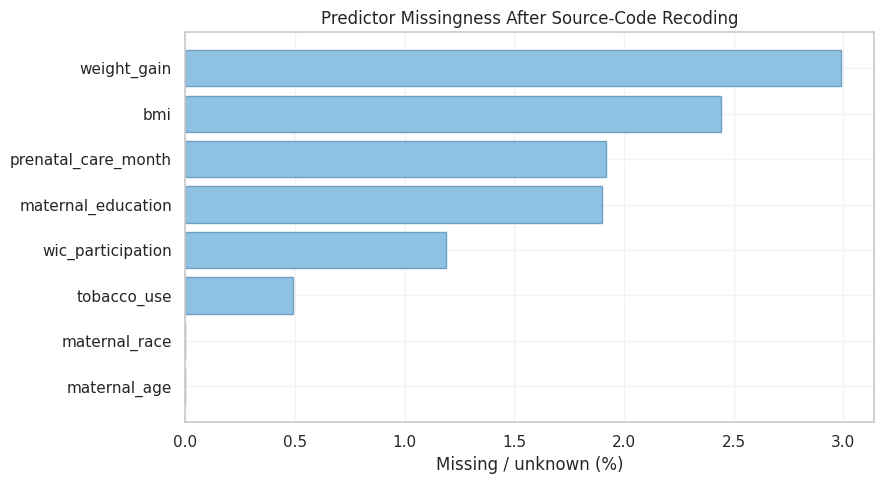

In [ ]:
#Missingness among predictors
final_missing = pd.DataFrame({
    'Missing Count': df_clean[FEATURE_COLS].isna().sum(),
    'Missing Percent': (df_clean[FEATURE_COLS].isna().mean() * 100).round(2),
})

plot_missing = final_missing.sort_values('Missing Percent')
plt.figure(figsize=(9, 5))
plt.barh(plot_missing.index, plot_missing['Missing Percent'], color='#8FC1E3', edgecolor='#70A1C4')
plt.xlabel('Missing / unknown (%)')
plt.title('Predictor Missingness After Source-Code Recoding')
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis

,Outcome,Positive Cases,Rows with Known Label,Prevalence (%)
0,Low Birth Weight,246464,3523530,6.99
1,Preterm Birth,373758,3521848,10.61
2,Preterm Low Birth Weight (PLBW),145490,3519989,4.13


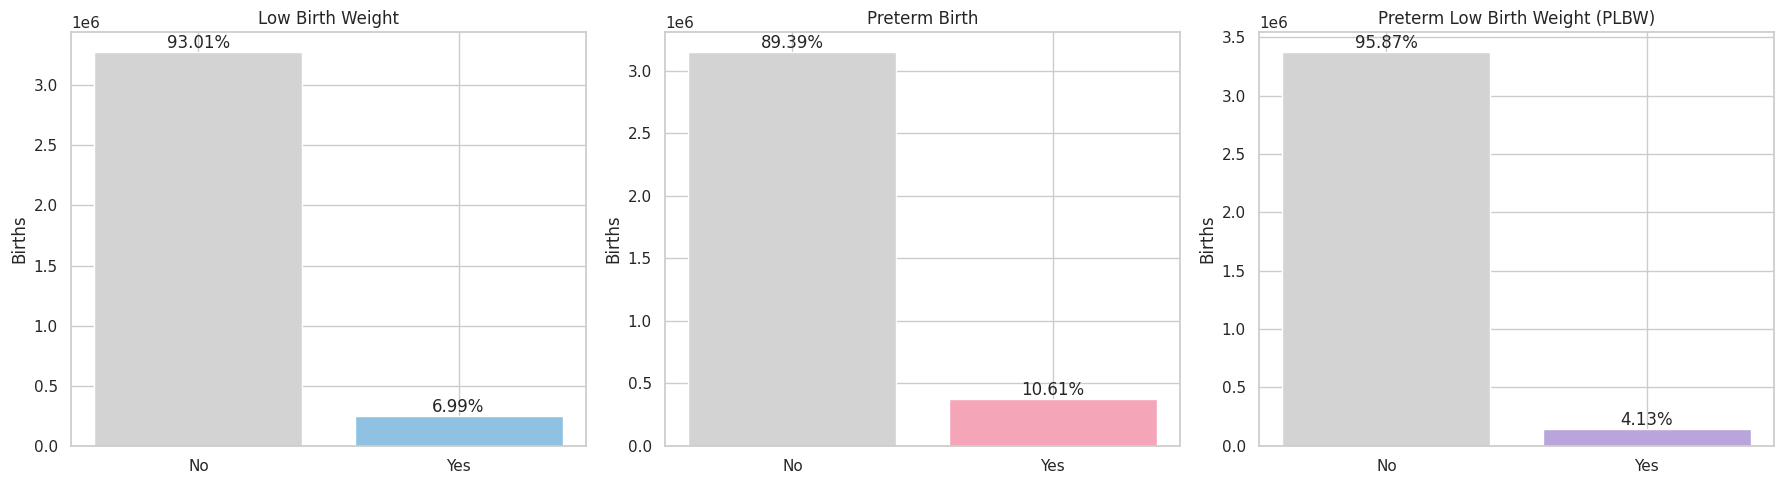

In [ ]:
# 4.1 Outcome prevalence
outcome_summary = pd.DataFrame({
    'Outcome': [cfg['label'] for cfg in TARGETS.values()],
    'Positive Cases': [int(df_clean[t].sum()) for t in TARGETS],
    'Rows with Known Label': [int(df_clean[t].notna().sum()) for t in TARGETS],
})
outcome_summary['Prevalence (%)'] = (100 * outcome_summary['Positive Cases'] / outcome_summary['Rows with Known Label']).round(2)
display(outcome_summary)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (t, cfg) in zip(axes, TARGETS.items()):
    counts = df_clean[t].value_counts().reindex([0, 1]).fillna(0)
    ax.bar(['No', 'Yes'], counts.values, color=['#d3d3d3', cfg['color']])
    ax.set_title(cfg['label'])
    ax.set_ylabel('Births')
    for i, value in enumerate(counts.values):
        ax.text(i, value, f'{value / counts.sum() * 100:.2f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

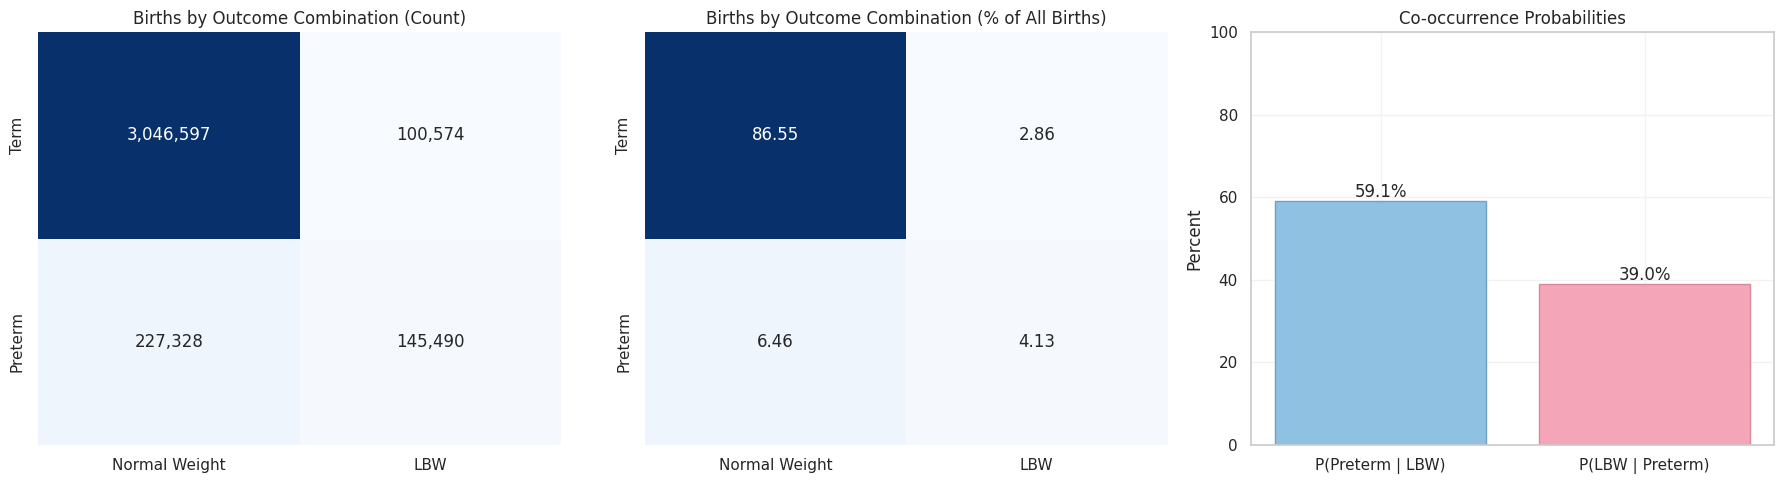

59.1% of low birth weight infants are also preterm.
39.0% of preterm infants are also low birth weight.


In [ ]:
# 4.2 Overlap between low birth weight and preterm birth
both = df_clean[['low_birth_weight', 'preterm_birth']].dropna().astype(int)

crosstab_counts = pd.crosstab(
    both['preterm_birth'].map({0: 'Term', 1: 'Preterm'}),
    both['low_birth_weight'].map({0: 'Normal Weight', 1: 'LBW'}),
).loc[['Term', 'Preterm'], ['Normal Weight', 'LBW']]
crosstab_pct = crosstab_counts / crosstab_counts.values.sum() * 100

p_ptb_given_lbw = both.loc[both['low_birth_weight'] == 1, 'preterm_birth'].mean() * 100
p_lbw_given_ptb = both.loc[both['preterm_birth'] == 1, 'low_birth_weight'].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Using the standard, normal 'Blues' colormap for both heatmaps
sns.heatmap(crosstab_counts, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Births by Outcome Combination (Count)')

sns.heatmap(crosstab_pct, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('Births by Outcome Combination (% of All Births)')

for ax in axes[:2]:
    ax.set_xlabel('')
    ax.set_ylabel('')

bars = axes[2].bar(['P(Preterm | LBW)', 'P(LBW | Preterm)'], [p_ptb_given_lbw, p_lbw_given_ptb], color=['#8FC1E3', '#F4A6B8'], edgecolor=['#70A1C4', '#D9899C'])
axes[2].bar_label(bars, fmt='%.1f%%')
axes[2].set_ylim(0, 100)
axes[2].set_ylabel('Percent')
axes[2].set_title('Co-occurrence Probabilities')
plt.tight_layout()
plt.show()

print(f'{p_ptb_given_lbw:.1f}% of low birth weight infants are also preterm.')
print(f'{p_lbw_given_ptb:.1f}% of preterm infants are also low birth weight.')

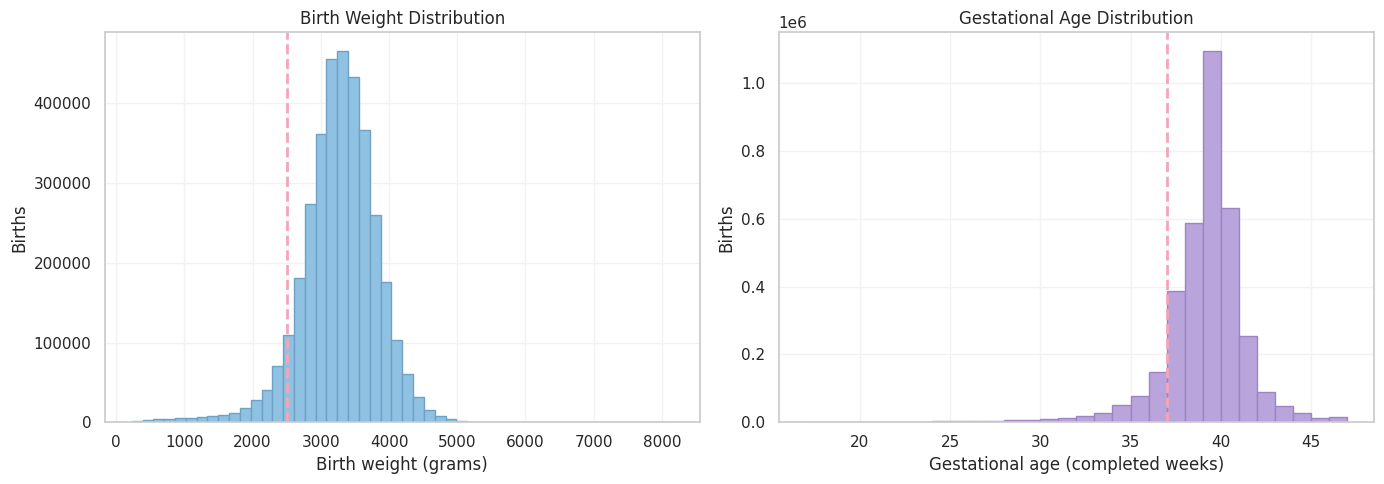

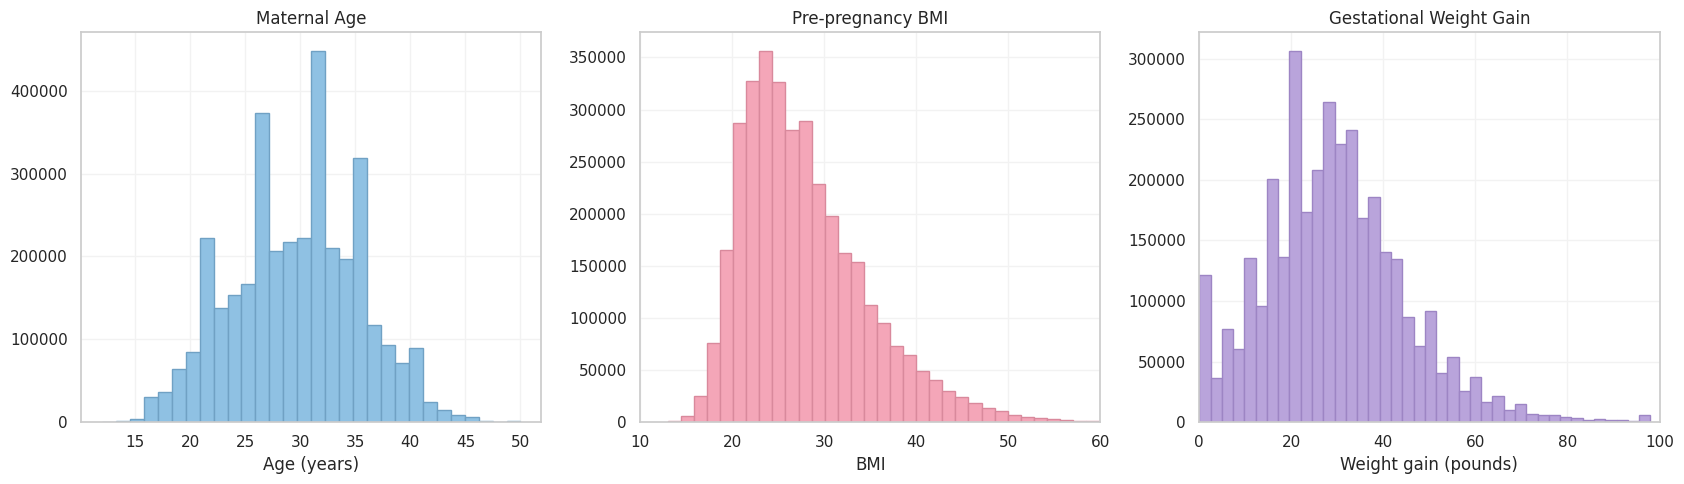

In [ ]:
# 4.3 Distributions: outcome source variables and continuous predictors
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_clean['birth_weight_grams'].dropna(), bins=50, color='#8FC1E3', edgecolor='#70A1C4')
axes[0].axvline(2500, linestyle='--', linewidth=2, color='#F4A6B8')
axes[0].set(title='Birth Weight Distribution', xlabel='Birth weight (grams)', ylabel='Births')
axes[1].hist(df_clean['gestational_age_weeks'].dropna(), bins=30, color='#B9A4DB', edgecolor='#9D85C4')
axes[1].axvline(37, linestyle='--', linewidth=2, color='#F4A6B8')
axes[1].set(title='Gestational Age Distribution', xlabel='Gestational age (completed weeks)', ylabel='Births')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].hist(df_clean['maternal_age'].dropna(), bins=30, color='#8FC1E3', edgecolor='#70A1C4')
axes[0].set(title='Maternal Age', xlabel='Age (years)')
axes[1].hist(df_clean['bmi'].dropna(), bins=40, color='#F4A6B8', edgecolor='#D9899C')
axes[1].set(title='Pre-pregnancy BMI', xlabel='BMI', xlim=(10, 60))
axes[2].hist(df_clean['weight_gain'].dropna(), bins=40, color='#B9A4DB', edgecolor='#9D85C4')
axes[2].set(title='Gestational Weight Gain', xlabel='Weight gain (pounds)', xlim=(0, 100))
plt.tight_layout()
plt.show()

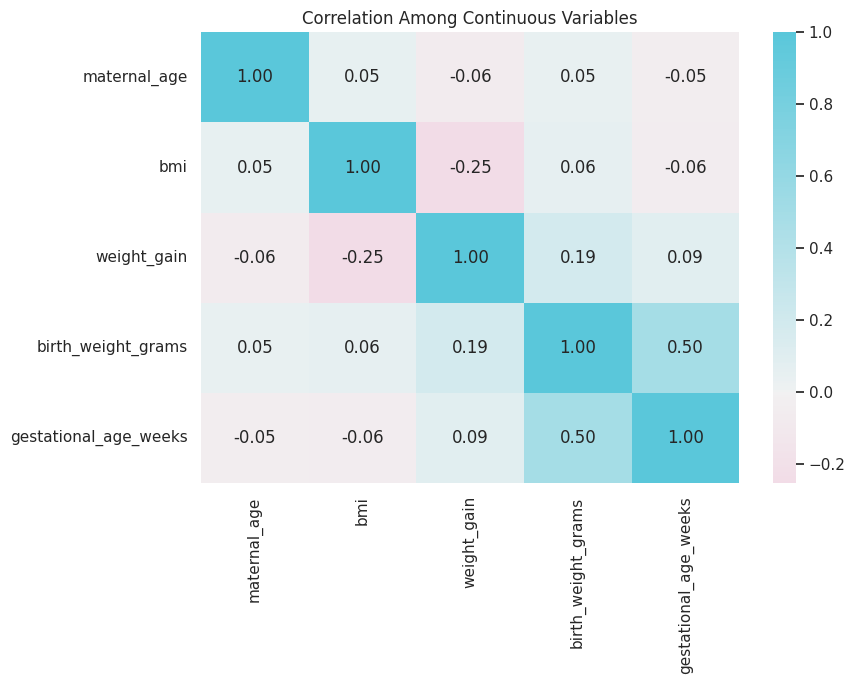

In [ ]:
# 4.4 Correlations among continuous variables
corr_cols = ['maternal_age', 'bmi', 'weight_gain', 'birth_weight_grams', 'gestational_age_weeks']
plt.figure(figsize=(9, 7))
# Custom color palette
baby_diverging = sns.diverging_palette(340, 210, s=80, l=75, n=256, as_cmap=True)
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt='.2f', center=0, cmap=baby_diverging)
plt.title('Correlation Among Continuous Variables')
plt.tight_layout()
plt.show()

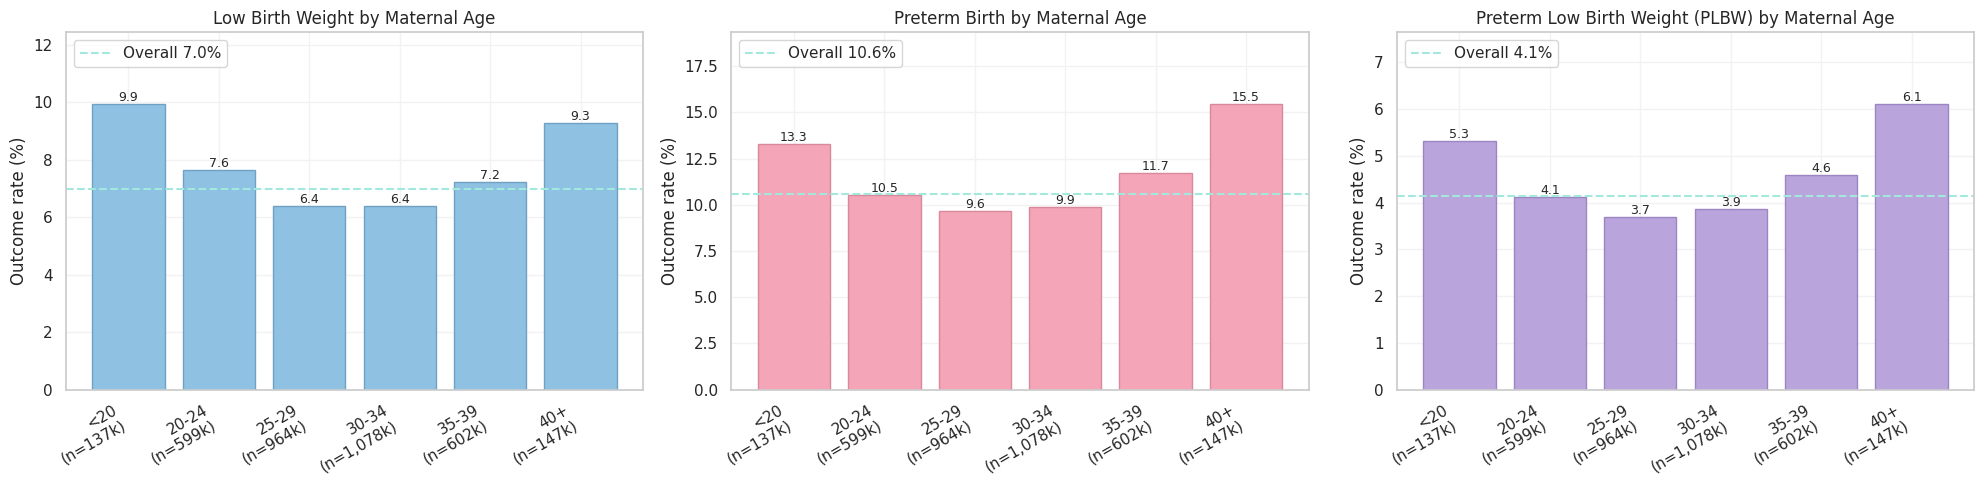

,Births,LBW,PTB,PLBW
age_group,,,,
<20,136960,9.95,13.27,5.31
20-24,598660,7.63,10.52,4.11
25-29,964226,6.38,9.64,3.69
30-34,1077709,6.38,9.90,3.87
35-39,601599,7.22,11.74,4.58
40+,147216,9.29,15.47,6.11


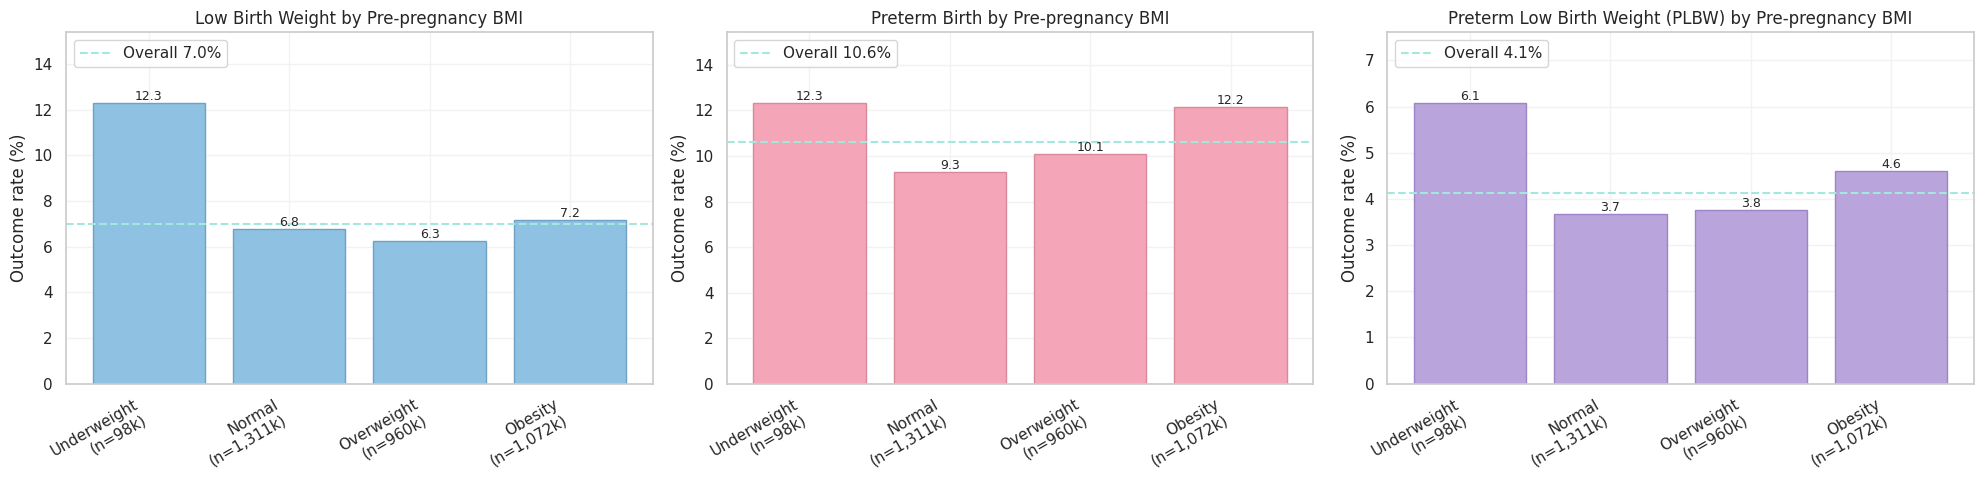

,Births,LBW,PTB,PLBW
bmi_group,,,,
Underweight,97704,12.31,12.34,6.08
Normal,1310620,6.77,9.31,3.68
Overweight,959781,6.26,10.09,3.76
Obesity,1072230,7.17,12.16,4.61


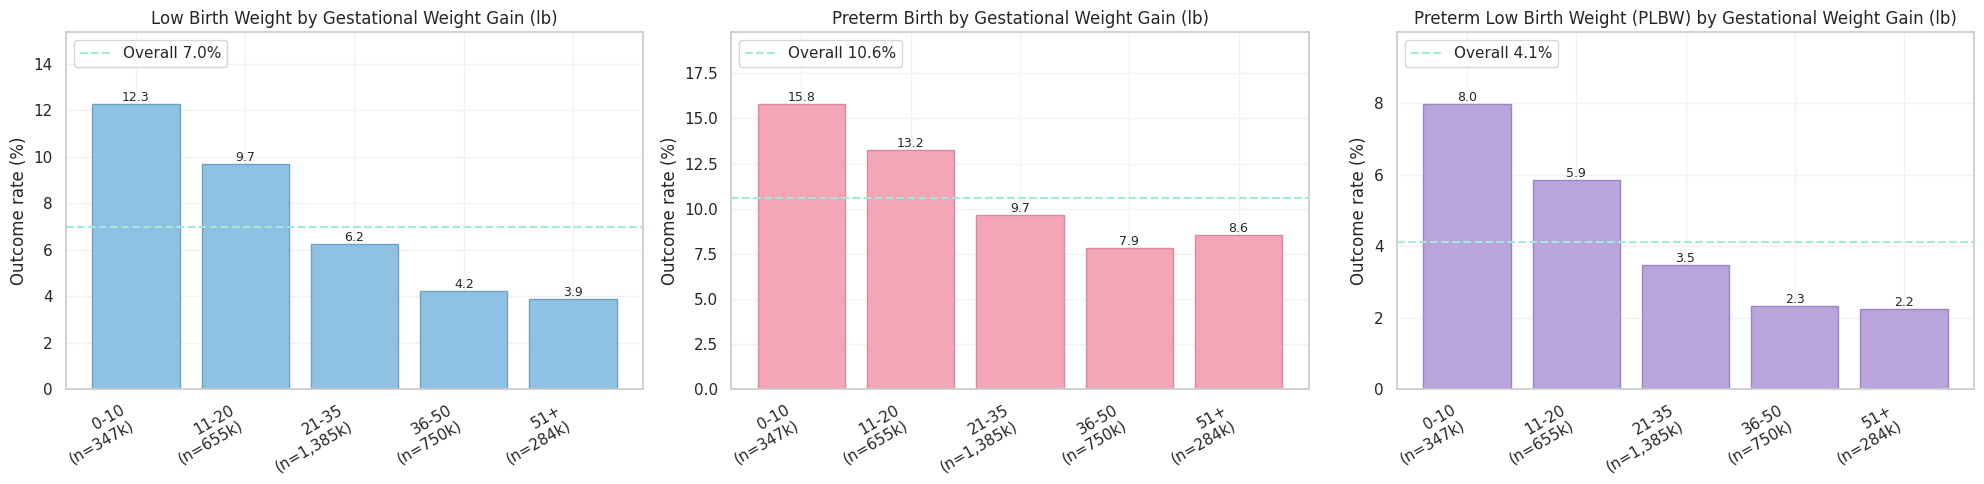

,Births,LBW,PTB,PLBW
weight_gain_group,,,,
0-10,347411,12.27,15.81,7.98
11-20,655134,9.69,13.24,5.86
21-35,1384658,6.24,9.66,3.48
36-50,749899,4.24,7.85,2.32
51+,283798,3.88,8.58,2.24


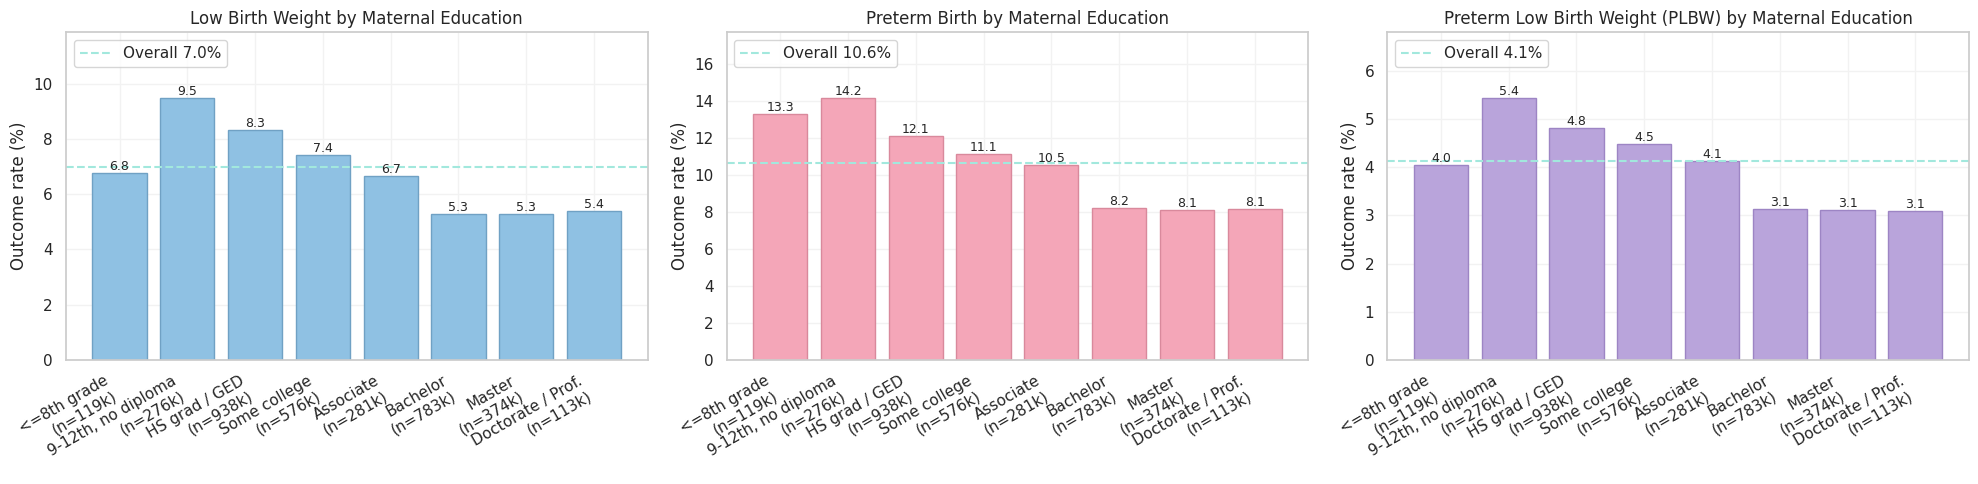

,Births,LBW,PTB,PLBW
education_group,,,,
<=8th grade,118611,6.77,13.27,4.04
"9-12th, no diploma",276395,9.48,14.15,5.44
HS grad / GED,938092,8.33,12.10,4.82
Some college,575641,7.40,11.12,4.48
Associate,281337,6.66,10.50,4.13
Bachelor,782672,5.30,8.22,3.14
Master,373587,5.27,8.11,3.11
Doctorate / Prof.,113082,5.39,8.14,3.08


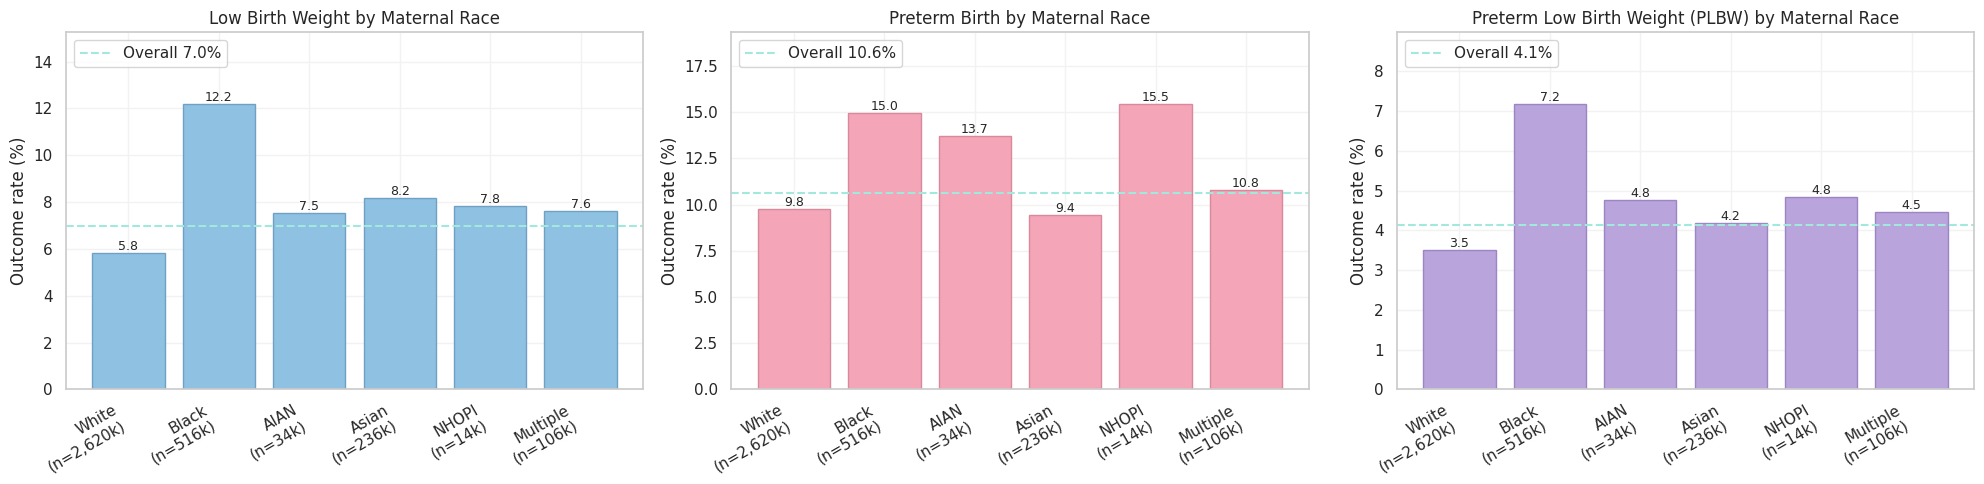

,Births,LBW,PTB,PLBW
race_group,,,,
White,2619891,5.83,9.79,3.50
Black,516038,12.20,14.95,7.19
AIAN,34408,7.53,13.74,4.76
Asian,235867,8.18,9.44,4.19
NHOPI,14055,7.84,15.46,4.83
Multiple,106111,7.61,10.81,4.47


In [ ]:
# 4.5 Outcome rates by predictor group (one helper, used for every predictor)
EDU_LABELS = {1: '<=8th grade', 2: '9-12th, no diploma', 3: 'HS grad / GED', 4: 'Some college',
              5: 'Associate', 6: 'Bachelor', 7: 'Master', 8: 'Doctorate / Prof.'}
RACE_LABELS = {1: 'White', 2: 'Black', 3: 'AIAN', 4: 'Asian', 5: 'NHOPI', 6: 'Multiple'}

eda = df_clean.copy()
eda['age_group'] = pd.cut(eda['maternal_age'], bins=[0, 19, 24, 29, 34, 39, np.inf],
                          labels=['<20', '20-24', '25-29', '30-34', '35-39', '40+'])
eda['bmi_group'] = pd.cut(eda['bmi'], bins=[0, 18.5, 25, 30, np.inf],
                          labels=['Underweight', 'Normal', 'Overweight', 'Obesity'])
eda['weight_gain_group'] = pd.cut(eda['weight_gain'], bins=[-1, 10, 20, 35, 50, np.inf],
                                  labels=['0-10', '11-20', '21-35', '36-50', '51+'])
eda['education_group'] = pd.Categorical(eda['maternal_education'].map(EDU_LABELS),
                                        categories=list(EDU_LABELS.values()), ordered=True)
eda['race_group'] = pd.Categorical(eda['maternal_race'].map(RACE_LABELS),
                                   categories=list(RACE_LABELS.values()))
eda['prenatal_care_month_group'] = eda['prenatal_care_month'].astype('Int64')

overall_rates = {t: eda[t].mean() * 100 for t in TARGETS}

def plot_rates_by_group(group_col, title):
    g = eda.groupby(group_col, observed=True).agg(
        Births=('low_birth_weight', 'size'),
        **{cfg['short']: (t, 'mean') for t, cfg in TARGETS.items()},
    )
    g[[cfg['short'] for cfg in TARGETS.values()]] *= 100
    tick_labels = [f'{idx}\n(n={n / 1000:,.0f}k)' for idx, n in zip(g.index, g['Births'])]

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    theme_edges = ['#70A1C4', '#D9899C', '#9D85C4']
    for ax, (t, cfg), edge_c in zip(axes, TARGETS.items(), theme_edges):
        bars = ax.bar(range(len(g)), g[cfg['short']], color=cfg['color'], edgecolor=edge_c)
        ax.bar_label(bars, fmt='%.1f', fontsize=9)
        ax.axhline(overall_rates[t], color='#A2E8DD', linestyle='--', linewidth=1.5,
                   label=f'Overall {overall_rates[t]:.1f}%')
        ax.set_xticks(range(len(g)))
        ax.set_xticklabels(tick_labels, rotation=30, ha='right')
        ax.set_ylabel('Outcome rate (%)')
        ax.set_title(f"{cfg['label']} by {title}")
        ax.set_ylim(0, max(g[cfg['short']].max(), overall_rates[t]) * 1.25)
        ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()
    display(g.round(2))

# Demographics and physical characteristics
for col, title in [('age_group', 'Maternal Age'),
                   ('bmi_group', 'Pre-pregnancy BMI'),
                   ('weight_gain_group', 'Gestational Weight Gain (lb)'),
                   ('education_group', 'Maternal Education'),
                   ('race_group', 'Maternal Race')]:
    plot_rates_by_group(col, title)

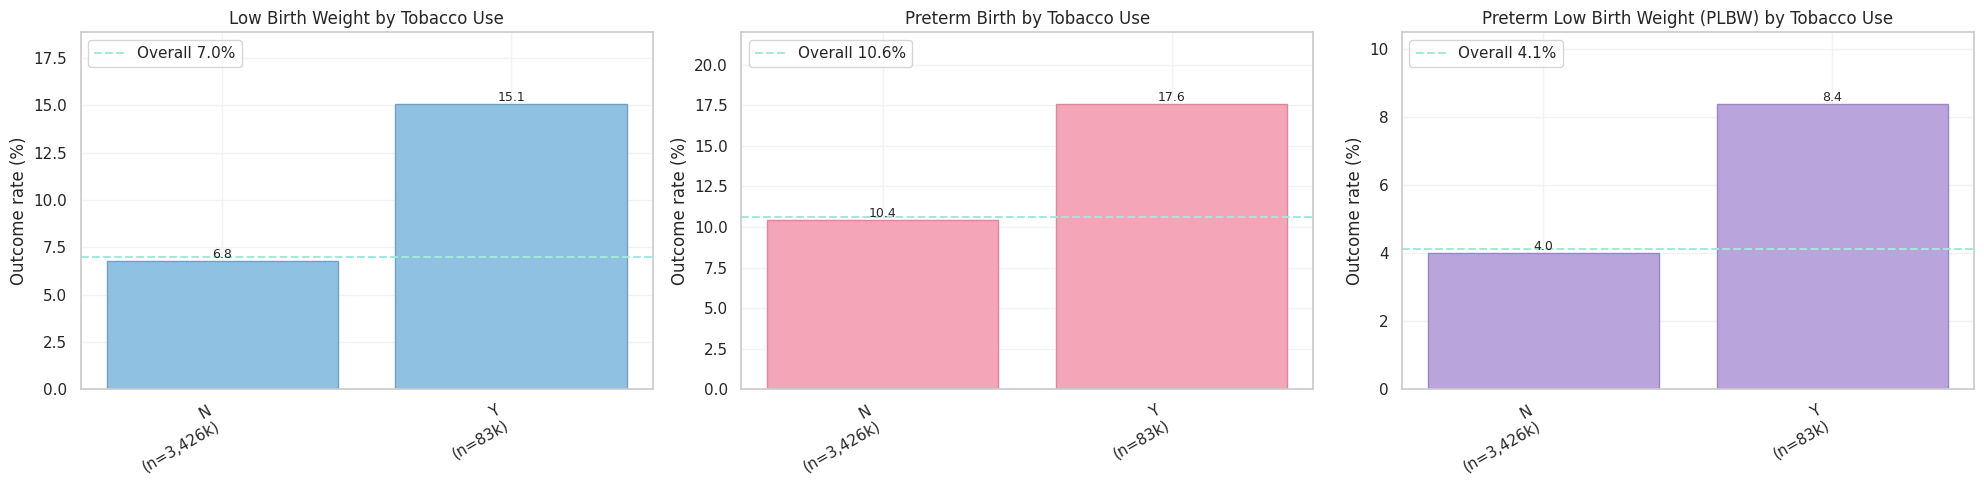

,Births,LBW,PTB,PLBW
tobacco_use,,,,
N,3425686,6.78,10.42,4.01
Y,83494,15.08,17.58,8.40


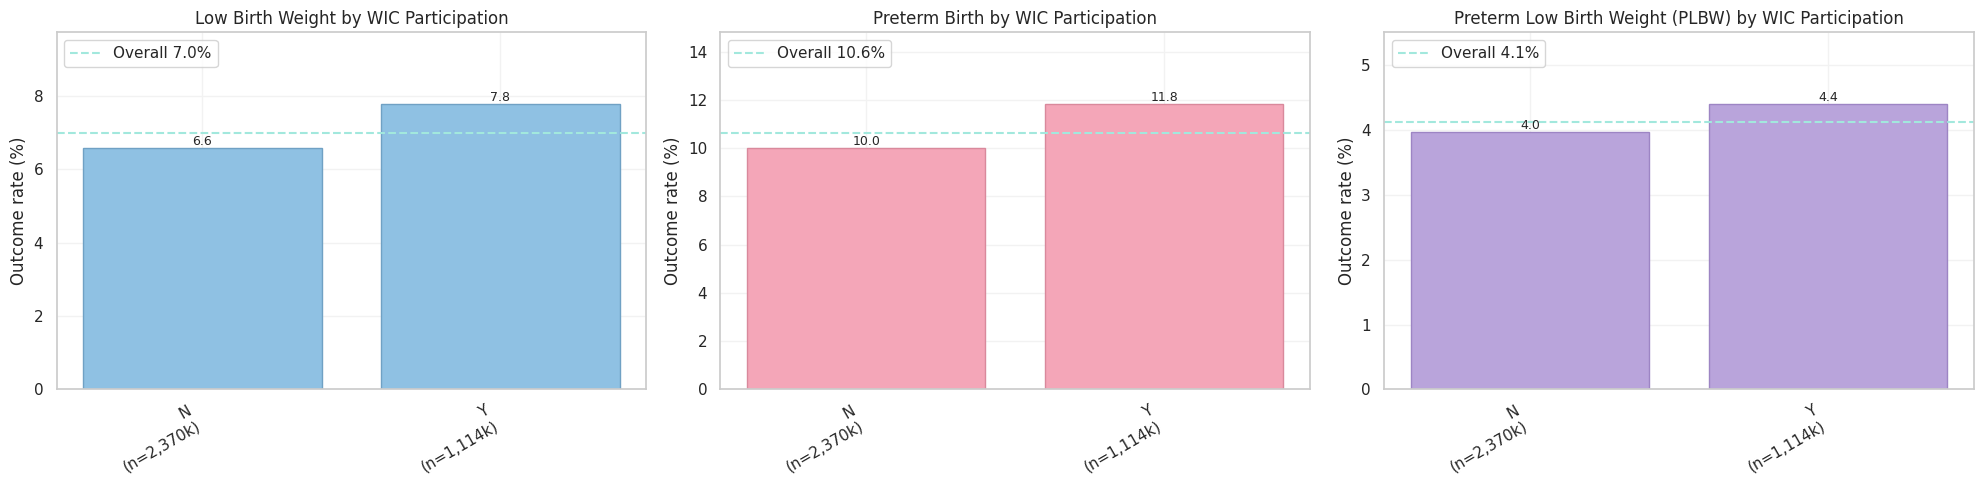

,Births,LBW,PTB,PLBW
wic_participation,,,,
N,2370149,6.58,10.00,3.97
Y,1114281,7.79,11.84,4.41


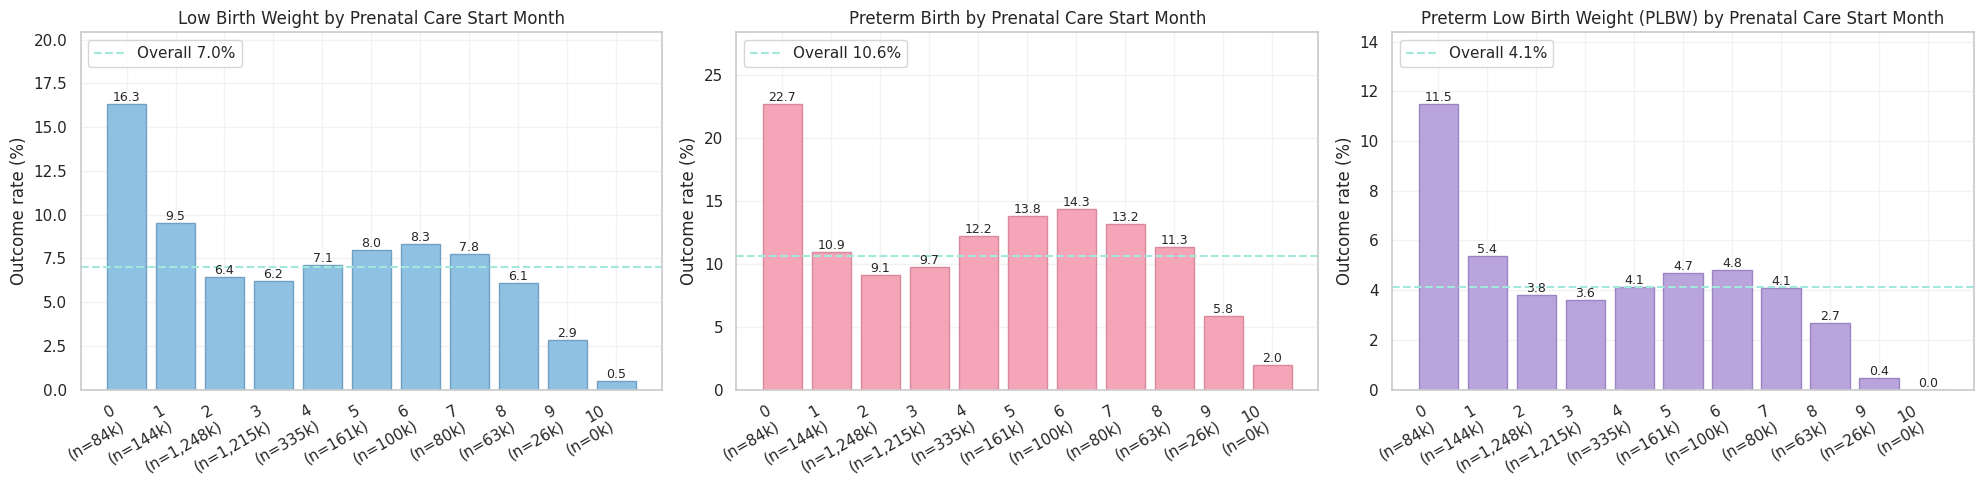

,Births,LBW,PTB,PLBW
prenatal_care_month_group,,,,
0,84473,16.34,22.70,11.50
1,144477,9.53,10.89,5.35
2,1248161,6.43,9.13,3.81
3,1215368,6.18,9.71,3.62
4,335390,7.11,12.23,4.13
5,161484,7.99,13.77,4.69
6,99719,8.32,14.35,4.81
7,80288,7.77,13.16,4.09
8,63015,6.11,11.29,2.68


In [ ]:
# Behaviors and prenatal care
for col, title in [('tobacco_use', 'Tobacco Use'),
                   ('wic_participation', 'WIC Participation'),
                   ('prenatal_care_month_group', 'Prenatal Care Start Month')]:
    plot_rates_by_group(col, title)

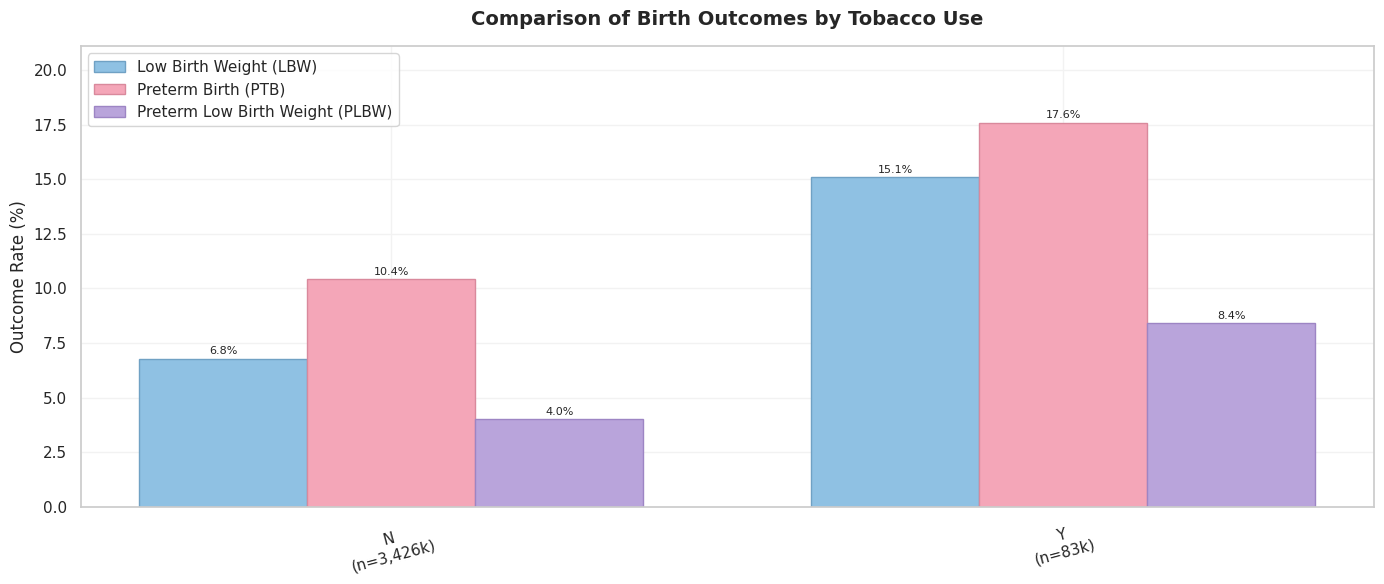

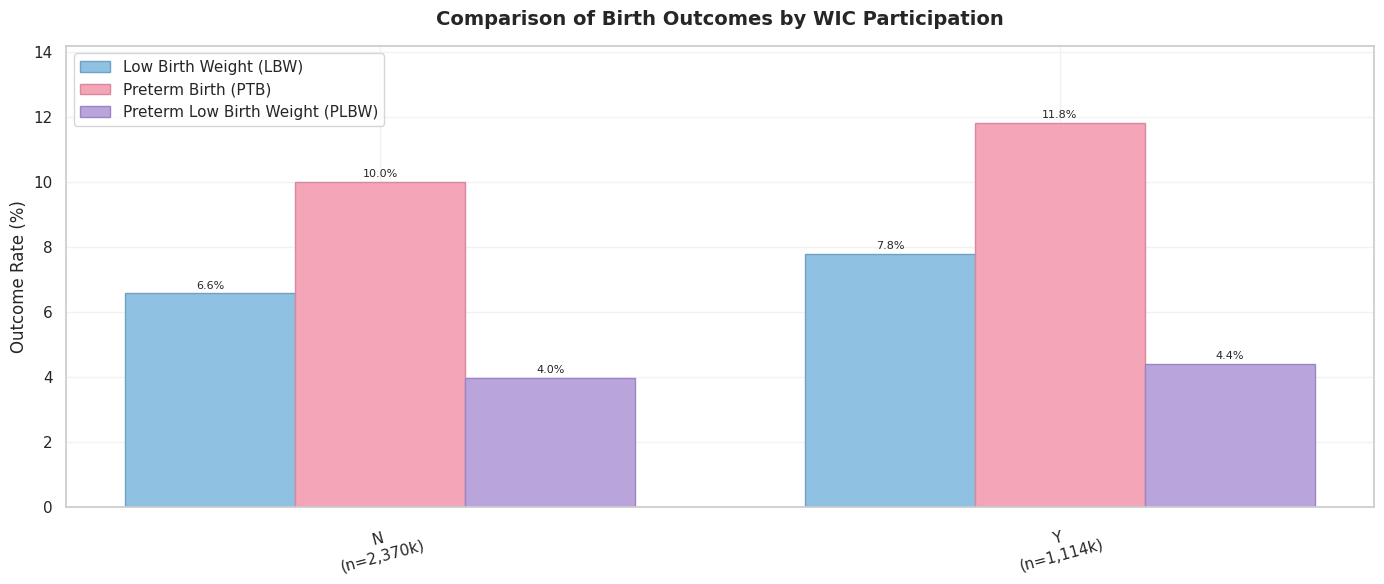

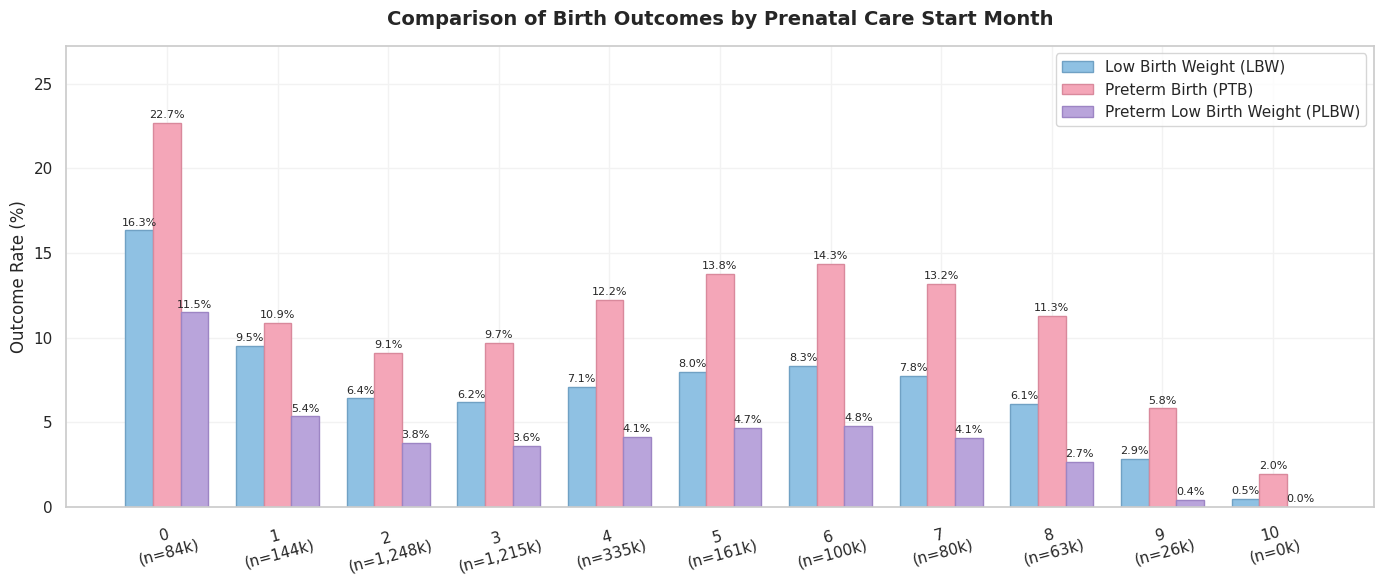

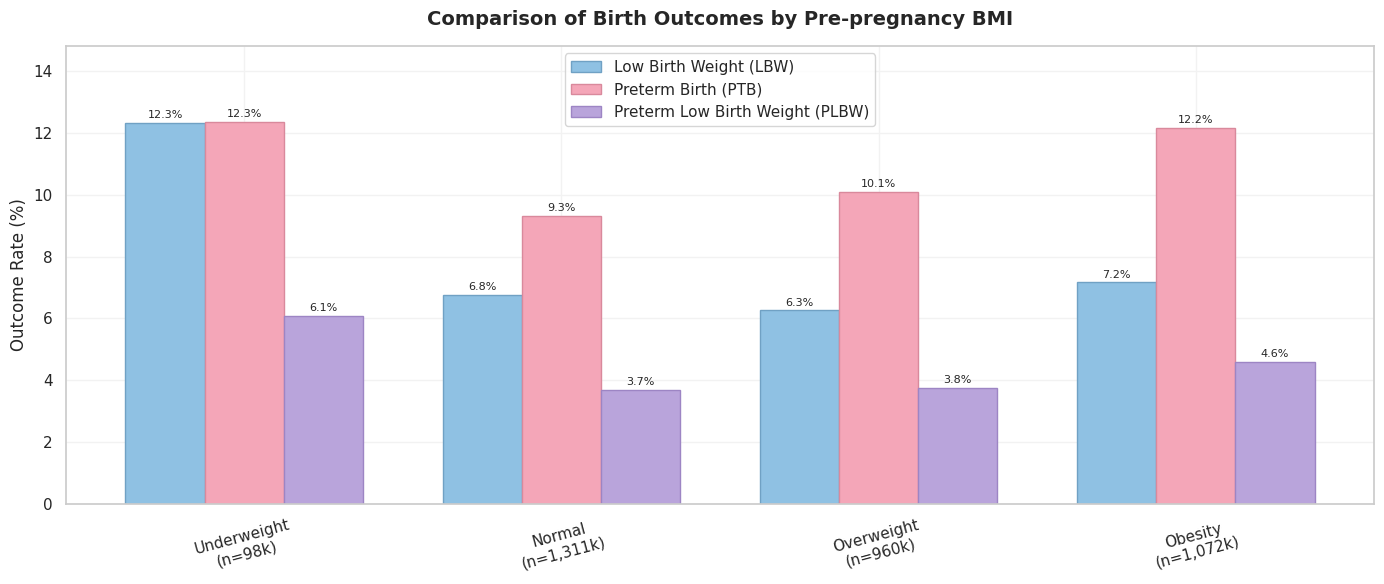

In [ ]:
# 4.6 Combined outcome rates for behaviors and prenatal care (all outcomes in one plot per feature)
import numpy as np

behaviors_list = [
    ('tobacco_use', 'Tobacco Use'),
    ('wic_participation', 'WIC Participation'),
    ('prenatal_care_month_group', 'Prenatal Care Start Month'),
    ('bmi_group', 'Pre-pregnancy BMI')
]

for col, title in behaviors_list:
    # Aggregate outcomes
    g = eda.groupby(col, observed=True).agg(
        Births=('low_birth_weight', 'size'),
        LBW=('low_birth_weight', 'mean'),
        PTB=('preterm_birth', 'mean'),
        PLBW=('combined_ptb_lbw', 'mean')
    )
    g[['LBW', 'PTB', 'PLBW']] *= 100

    x = np.arange(len(g))
    width = 0.25

    plt.figure(figsize=(14, 6))

    # Plot grouped bars representing the three outcomes
    bar1 = plt.bar(x - width, g['LBW'], width, label='Low Birth Weight (LBW)', color='#8FC1E3', edgecolor='#70A1C4')
    bar2 = plt.bar(x, g['PTB'], width, label='Preterm Birth (PTB)', color='#F4A6B8', edgecolor='#D9899C')
    bar3 = plt.bar(x + width, g['PLBW'], width, label='Preterm Low Birth Weight (PLBW)', color='#B9A4DB', edgecolor='#9D85C4')

    # Add exact labels on top of the bars
    plt.bar_label(bar1, fmt='%.1f%%', fontsize=8, padding=2)
    plt.bar_label(bar2, fmt='%.1f%%', fontsize=8, padding=2)
    plt.bar_label(bar3, fmt='%.1f%%', fontsize=8, padding=2)

    plt.title(f'Comparison of Birth Outcomes by {title}', fontsize=14, fontweight='bold', pad=15)
    plt.ylabel('Outcome Rate (%)')

    tick_labels = [f'{idx}\n(n={n / 1000:,.0f}k)' for idx, n in zip(g.index, g['Births'])]
    plt.xticks(x, tick_labels, rotation=15)
    plt.ylim(0, max(g[['LBW', 'PTB', 'PLBW']].values.max() * 1.2, 5))
    plt.legend()
    plt.tight_layout()
    plt.show()

## 5. Splits, Models, and Training

For each target, the cohort is every birth with a known label for that target, split 70% train / 15% validation / 15% test (stratified on the label). The validation set is used only for threshold selection; the test set is used once, in Section 6.

Each model gets a fresh preprocessing pipeline (median-impute + scale numerics, mode-impute + one-hot categoricals) so that no fitted state is shared across targets or models.

In [ ]:
def split_target(df, target):
    """Cohort = rows with a known label. Returns {'train'|'val'|'test': (X, y)}."""
    data = df.loc[df[target].notna(), FEATURE_COLS + [target]]
    X = data[FEATURE_COLS].copy()
    y = data[target].astype(int)
    X[CATEGORICAL_COLS] = X[CATEGORICAL_COLS].astype('object')

    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
    return {'train': (X_train, y_train), 'val': (X_val, y_val), 'test': (X_test, y_test)}


def make_preprocessor():
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num', numeric, NUMERIC_COLS),
                              ('cat', categorical, CATEGORICAL_COLS)])


def make_model(model_name, y_train):
    """Return an unfitted pipeline (fresh preprocessor + classifier) for one model."""
    if model_name == 'Logistic Regression':
        clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
    elif model_name == 'Random Forest':
        clf = RandomForestClassifier(n_estimators=50, max_depth=12, class_weight='balanced',
                                     n_jobs=-1, random_state=RANDOM_STATE)
    elif model_name == 'XGBoost':
        scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()
        clf = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
                            n_jobs=-1, eval_metric='logloss', random_state=RANDOM_STATE)
    else:
        raise ValueError(f'Unknown model: {model_name}')
    return Pipeline([('preprocessor', make_preprocessor()), ('classifier', clf)])

In [ ]:
splits = {t: split_target(df_clean, t) for t in TARGETS}

display(pd.DataFrame({
    cfg['label']: {
        'Train': len(splits[t]['train'][0]),
        'Validation': len(splits[t]['val'][0]),
        'Test': len(splits[t]['test'][0]),
        'Prevalence (%)': round(pd.concat([splits[t][s][1] for s in splits[t]]).mean() * 100, 2),
    } for t, cfg in TARGETS.items()
}).T)

models = {t: {} for t in TARGETS}
for t, cfg in TARGETS.items():
    X_train, y_train = splits[t]['train']
    for model_name in MODEL_NAMES:
        print(f"Training {model_name} for {cfg['label']}...")
        models[t][model_name] = make_model(model_name, y_train).fit(X_train, y_train)
print('\nAll 9 models trained.')

,Train,Validation,Test,Prevalence (%)
Low Birth Weight,2466471.0,528529.0,528530.0,6.99
Preterm Birth,2465293.0,528277.0,528278.0,10.61
Preterm Low Birth Weight (PLBW),2463992.0,527998.0,527999.0,4.13


Training Logistic Regression for Low Birth Weight...
Training Random Forest for Low Birth Weight...
Training XGBoost for Low Birth Weight...
Training Logistic Regression for Preterm Birth...
Training Random Forest for Preterm Birth...
Training XGBoost for Preterm Birth...
Training Logistic Regression for Preterm Low Birth Weight (PLBW)...
Training Random Forest for Preterm Low Birth Weight (PLBW)...
Training XGBoost for Preterm Low Birth Weight (PLBW)...

All 9 models trained.


## 6. Threshold Selection and Test-Set Evaluation

In [ ]:
def select_threshold_by_f1(model, X_val, y_val):
    """Return (threshold, F1) that maximizes F1 on the validation set."""
    prob = model.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, prob)
    precision, recall = precision[:-1], recall[:-1]          # align with thresholds
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    best = int(np.argmax(f1))
    return float(thresholds[best]), float(f1[best])


def evaluate_model(model, X, y, threshold, target_label, model_name):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)
    return {
        'Target': target_label,
        'Model': model_name,
        'Threshold': round(threshold, 4),
        'PR-AUC': average_precision_score(y, prob),
        'Recall': recall_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0),
        'F1': f1_score(y, pred),
        'ROC-AUC': roc_auc_score(y, prob),
    }


thresholds = {}
results = []
for t, cfg in TARGETS.items():
    X_val, y_val = splits[t]['val']
    X_test, y_test = splits[t]['test']
    for model_name, model in models[t].items():
        thresholds[(t, model_name)], _ = select_threshold_by_f1(model, X_val, y_val)
        results.append(evaluate_model(model, X_test, y_test, thresholds[(t, model_name)],
                                      cfg['label'], model_name))

results_df = pd.DataFrame(results)
display(results_df.round(4))

print('Test-set PR-AUC (primary metric), by target and model:')
display(results_df.pivot(index='Target', columns='Model', values='PR-AUC')[MODEL_NAMES]
        .loc[[cfg['label'] for cfg in TARGETS.values()]].round(4))

,Target,Model,Threshold,PR-AUC,Recall,Precision,F1,ROC-AUC
0,Low Birth Weight,Logistic Regression,0.5772,0.1346,0.3712,0.1345,0.1975,0.6567
1,Low Birth Weight,Random Forest,0.5782,0.1475,0.3538,0.1503,0.2110,0.6715
2,Low Birth Weight,XGBoost,0.6172,0.1545,0.3352,0.1616,0.2181,0.6777
3,Preterm Birth,Logistic Regression,0.5045,0.1513,0.5317,0.1414,0.2234,0.6033
4,Preterm Birth,Random Forest,0.5280,0.1686,0.4278,0.1626,0.2356,0.6251
5,Preterm Birth,XGBoost,0.5316,0.1743,0.4607,0.1612,0.2388,0.6296
6,Preterm Low Birth Weight (PLBW),Logistic Regression,0.6109,0.0842,0.3028,0.0904,0.1393,0.6629
7,Preterm Low Birth Weight (PLBW),Random Forest,0.6186,0.0938,0.2660,0.1071,0.1527,0.6804
8,Preterm Low Birth Weight (PLBW),XGBoost,0.6505,0.1008,0.2764,0.1116,0.1590,0.6879


Test-set PR-AUC (primary metric), by target and model:


Model,Logistic Regression,Random Forest,XGBoost
Target,,,
Low Birth Weight,0.1346,0.1475,0.1545
Preterm Birth,0.1513,0.1686,0.1743
Preterm Low Birth Weight (PLBW),0.0842,0.0938,0.1008


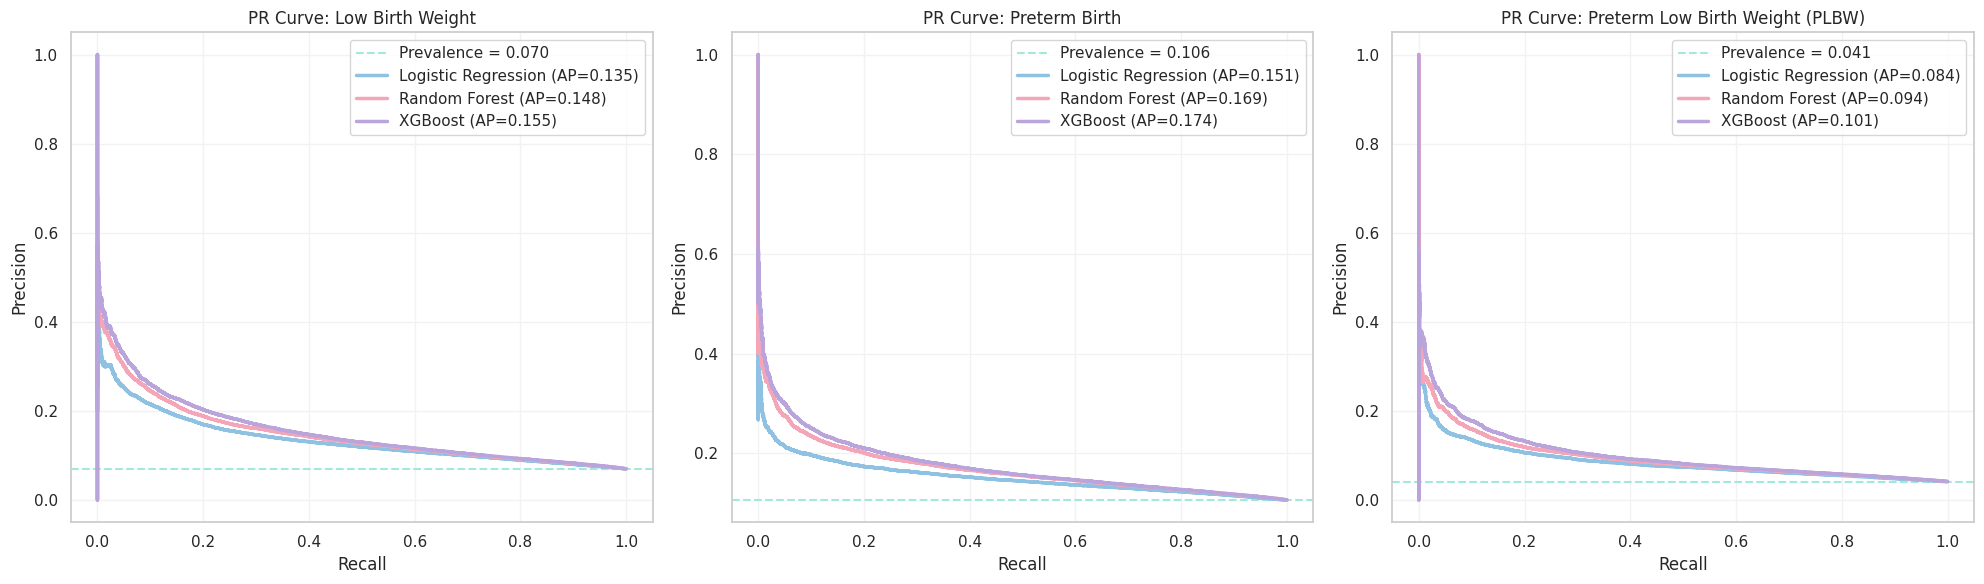

In [ ]:
# Precision-recall curves on the test set
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
# Harmonized palette for model curves matching the theme
curve_colors = ['#8FC1E3', '#F4A6B8', '#B9A4DB']
for ax, (t, cfg) in zip(axes, TARGETS.items()):
    X_test, y_test = splits[t]['test']
    ax.axhline(y_test.mean(), linestyle='--', linewidth=1.5, color='#A2E8DD', label=f'Prevalence = {y_test.mean():.3f}')
    for i, (model_name, model) in enumerate(models[t].items()):
        prob = model.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, prob)
        ax.plot(recall, precision, color=curve_colors[i], linewidth=2.5, label=f'{model_name} (AP={average_precision_score(y_test, prob):.3f})')
    ax.set(title=f"PR Curve: {cfg['label']}", xlabel='Recall', ylabel='Precision')
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Model Interpretation (SHAP)

SHAP summaries for the XGBoost model of each target, on a random sample of up to 10,000 test-set births.

SHAP summary: Low Birth Weight


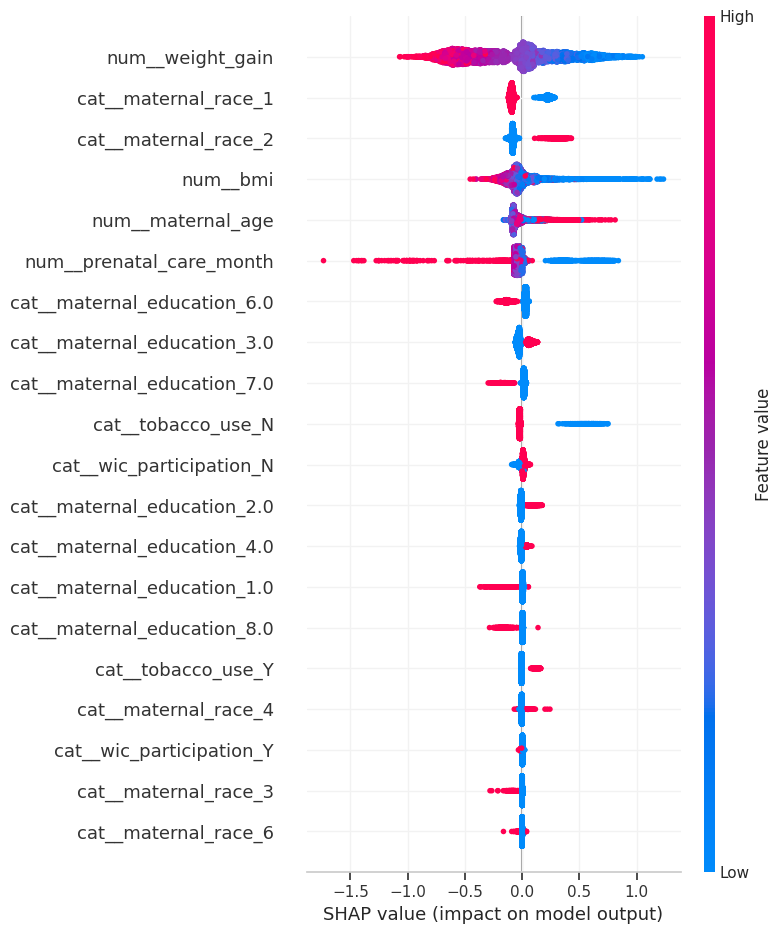

SHAP summary: Preterm Birth


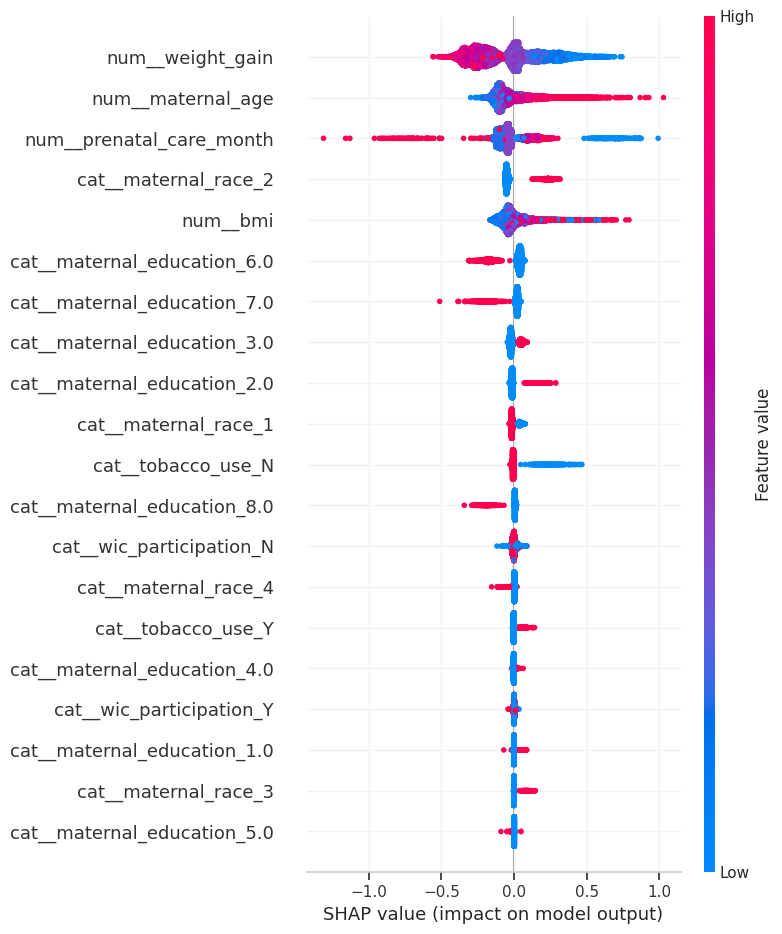

SHAP summary: Preterm Low Birth Weight (PLBW)


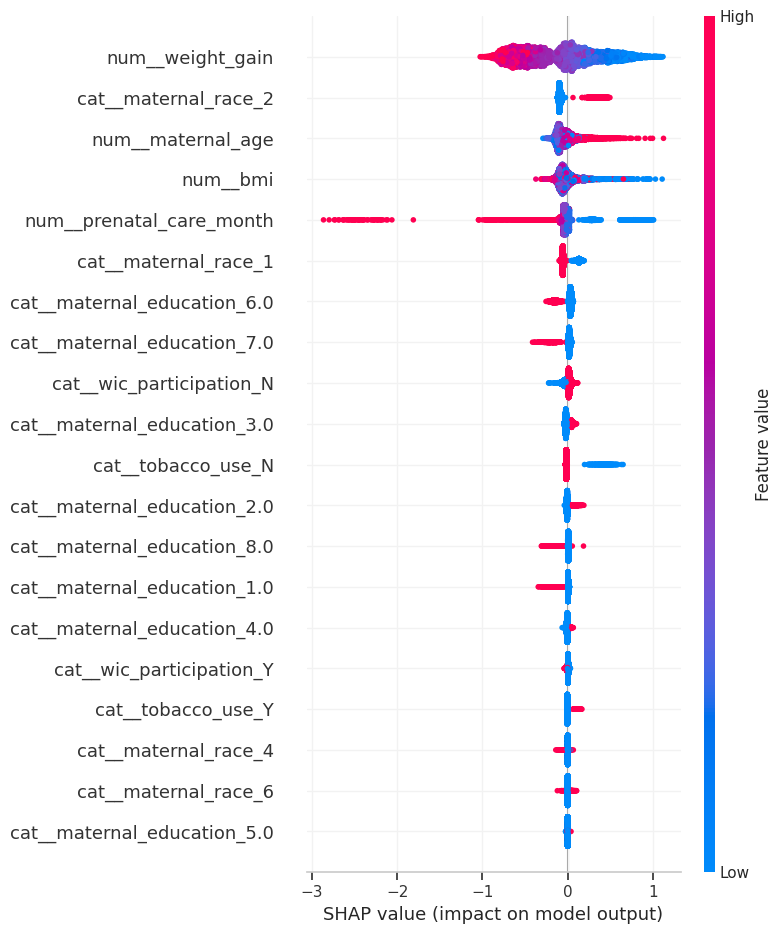

In [ ]:
for t, cfg in TARGETS.items():
    X_test, _ = splits[t]['test']
    X_sample = X_test.sample(min(10_000, len(X_test)), random_state=RANDOM_STATE)

    fitted = models[t]['XGBoost']
    preprocessor, classifier = fitted.named_steps['preprocessor'], fitted.named_steps['classifier']
    X_transformed = preprocessor.transform(X_sample)
    if hasattr(X_transformed, 'toarray'):
        X_transformed = X_transformed.toarray()

    shap_values = shap.TreeExplainer(classifier).shap_values(X_transformed)
    print(f"SHAP summary: {cfg['label']}")
    shap.summary_plot(shap_values, X_transformed,
                      feature_names=preprocessor.get_feature_names_out(), show=True)

## 8. Discussion and Limitations

- **Which model performs best for each target, and by how much over the prevalence baseline?**
- **Do the three targets behave differently?** (e.g., is the combined outcome easier or harder to predict than either component?)
- **Top predictors** from SHAP, and whether they are consistent across targets.
- **Limitations to address:**
  - Predictors are limited to maternal demographics, behaviors, and prenatal care; no clinical history (prior preterm birth, hypertension, diabetes) is included.
  - Total gestational weight gain is only known at delivery and tends to be larger in longer pregnancies, so it can carry information about the outcome itself. Consider this when interpreting its importance.
  - Single year of data (2024); results may not generalize across years.
  - Class imbalance is handled with class weights and tuned thresholds; the threshold choice (F1) trades off precision and recall and should be revisited for any real screening use.